<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/video8_foto_3d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧊 Convierte cualquier foto en 3D con 5 líneas de Python
**Laboratorio de Códigos** · Depth Anything V2 + OpenCV + Plotly

In [ ]:
from google.colab import files
subido = files.upload()          # sube tu foto (paisajes, retratos y calles se ven increíbles)
FOTO = next(iter(subido))

Saving publicco-ocean-2203720_1920.jpg to publicco-ocean-2203720_1920.jpg


## Las 5 líneas

In [ ]:
from transformers import pipeline
from PIL import Image
prof = pipeline("depth-estimation", model="depth-anything/Depth-Anything-V2-Small-hf")
mapa = prof(Image.open(FOTO).convert("RGB"))["depth"]
mapa.save("profundidad.png")

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

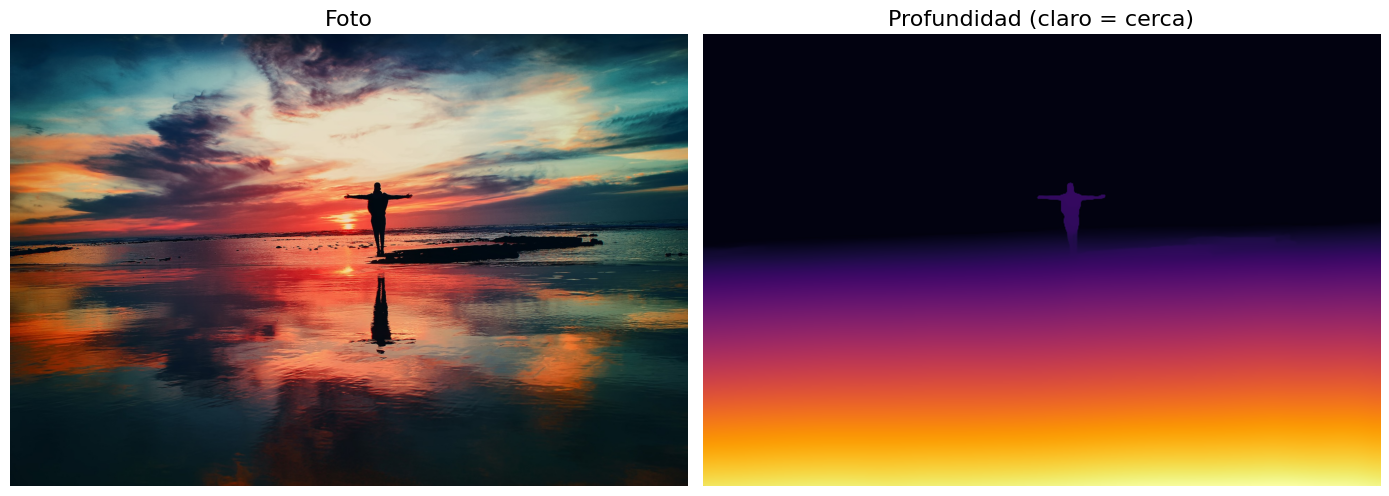

In [ ]:
import numpy as np, matplotlib.pyplot as plt
foto = np.array(Image.open(FOTO).convert("RGB"))
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(foto); ax[0].set_title("Foto", fontsize=16)
ax[1].imshow(np.array(mapa), cmap="inferno"); ax[1].set_title("Profundidad (claro = cerca)", fontsize=16)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Bonus 1: efecto 3D en movimiento (parallax)
Movemos cada píxel según su profundidad: lo cercano se mueve más que el fondo.

In [ ]:
import cv2

AMPLITUD = 0.03        # cuánto se mueve (fracción del ancho)
SEGUNDOS, FPS = 4, 30

img = foto[:, :, ::-1]
H, W = img.shape[:2]
d = cv2.resize(np.array(mapa).astype("float32"), (W, H))
d = (d - d.min()) / (d.max() - d.min() + 1e-6)
d = cv2.GaussianBlur(d, (0, 0), 3)                     # suaviza bordes
gx, gy = np.meshgrid(np.arange(W, dtype="float32"), np.arange(H, dtype="float32"))

out = cv2.VideoWriter("parallax_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
for t in np.linspace(0, 2 * np.pi, SEGUNDOS * FPS, endpoint=False):
    dx = (d - 0.5) * AMPLITUD * W * np.sin(t)
    dy = (d - 0.5) * AMPLITUD * H * 0.5 * np.cos(t)
    cuadro = cv2.remap(img, (gx + dx).astype("float32"), (gy + dy).astype("float32"), cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    m = int(AMPLITUD * W)                                # recorta y re-escala para ocultar bordes
    out.write(cv2.resize(cuadro[m:H - m, m:W - m], (W, H)))
out.release()

In [ ]:
SALIDA = "foto_3d.mp4"
!ffmpeg -y -loglevel error -i parallax_raw.mp4 -c:v libx264 -preset veryfast -pix_fmt yuv420p {SALIDA}

from base64 import b64encode
from IPython.display import HTML
datos = b64encode(open(SALIDA, "rb").read()).decode()
HTML(f'<video width=720 controls autoplay loop><source src="data:video/mp4;base64,{datos}" type="video/mp4"></video>')

## Bonus 2: la foto como nube de puntos 3D (gírala con el mouse)

In [ ]:
import plotly.graph_objects as go

ANCHO = 240
peq = cv2.resize(foto, (ANCHO, int(foto.shape[0] * ANCHO / foto.shape[1])))
dp = cv2.resize(d, (peq.shape[1], peq.shape[0]))
yy, xx = np.mgrid[0:peq.shape[0], 0:peq.shape[1]]
fig = go.Figure(go.Scatter3d(
    x=xx.ravel(), y=dp.ravel() * ANCHO * 0.6, z=-yy.ravel(), mode="markers",
    marker=dict(size=2, color=[f"rgb({r},{g},{b})" for r, g, b in peq.reshape(-1, 3)])))
fig.update_layout(scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False),
                  margin=dict(l=0, r=0, t=0, b=0), height=650)
fig.show()

In [ ]:
files.download(SALIDA)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>